# Qiskit Fall Fest 2026 - Vishnu Institute of Technology
## Challenge 3: Can you change the correlation?

In this challenge, we start with the standard Bell state where two qubits are strongly correlated, and then modify the circuit by adding one quantum gate to see if we can change the relationship between the measurement outcomes.

In [1]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

simulator = AerSimulator()
shots = 100

### Think Before You Run (Predictions)

1. **Original Bell Circuit:**
   - We apply an H gate on qubit 0 and a CNOT from qubit 0 to qubit 1.
   - This creates the entangled Bell state: $|\Phi^+\rangle = \frac{|00\rangle + |11\rangle}{\sqrt{2}}$.
   - **Prediction:** Outcomes `00` and `11` will dominate (~50% each). Both qubits will always produce the same measurement outcome.

2. **Modified Circuit:**
   - We add one X gate on qubit 1 after the CNOT gate.
   - The X gate flips qubit 1: $|00\rangle \to |01\rangle$ and $|11\rangle \to |10\rangle$.
   - This transforms the state into: $|\Psi^+\rangle = \frac{|01\rangle + |10\rangle}{\sqrt{2}}$.
   - **Prediction:** `01` and `10` will now dominate (~50% each). The qubits will produce opposite outcomes instead of the same outcomes.

In [2]:
# 1. Original Bell State Circuit
qc_orig = QuantumCircuit(2, 2)
qc_orig.h(0)
qc_orig.cx(0, 1)
qc_orig.measure([0, 1], [0, 1])

print(qc_orig.draw('text'))

counts_orig = simulator.run(qc_orig, shots=shots).result().get_counts()
print("\nOriginal counts (100 shots):", counts_orig)

     ┌───┐     ┌─┐   
q_0: ┤ H ├──■──┤M├───
     └───┘┌─┴─┐└╥┘┌─┐
q_1: ─────┤ X ├─╫─┤M├
          └───┘ ║ └╥┘
c: 2/═══════════╩══╩═
                0  1 

Original counts (100 shots): {'11': 46, '00': 54}


In [3]:
# 2. Modified Circuit (added 1 X gate on qubit 1)
qc_mod = QuantumCircuit(2, 2)
qc_mod.h(0)
qc_mod.cx(0, 1)
qc_mod.x(1)   # Added 1 quantum gate
qc_mod.measure([0, 1], [0, 1])

print(qc_mod.draw('text'))

counts_mod = simulator.run(qc_mod, shots=shots).result().get_counts()
print("\nModified counts (100 shots):", counts_mod)

     ┌───┐          ┌─┐   
q_0: ┤ H ├──■───────┤M├───
     └───┘┌─┴─┐┌───┐└╥┘┌─┐
q_1: ─────┤ X ├┤ X ├─╫─┤M├
          └───┘└───┘ ║ └╥┘
c: 2/════════════════╩══╩═
                     0  1 

Modified counts (100 shots): {'10': 53, '01': 47}


### Histograms

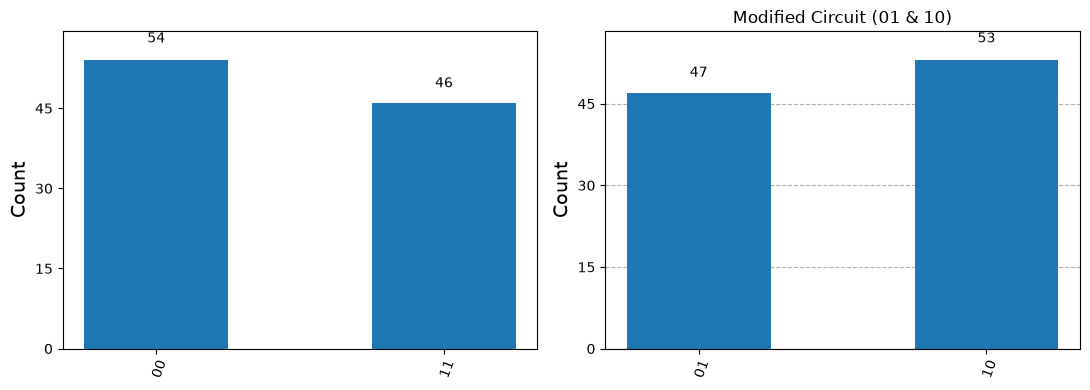

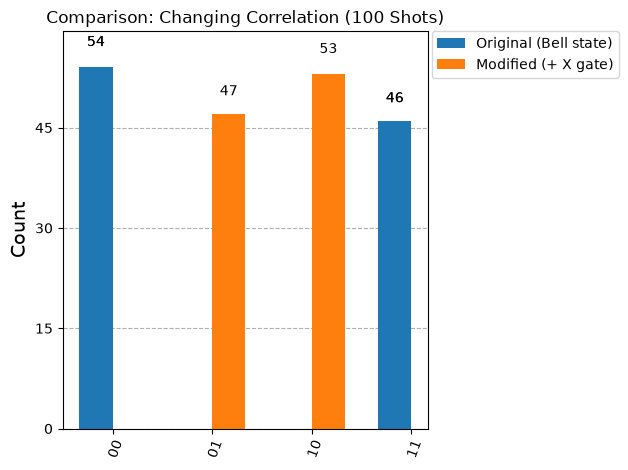

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
plot_histogram(counts_orig, ax=axes[0], title="Original: Correlated (00 & 11)")
plot_histogram(counts_mod, ax=axes[1], title="Modified: Anti-correlated (01 & 10)")
plt.tight_layout()
plt.show()

plot_histogram([counts_orig, counts_mod], 
               legend=["Original", "Modified"], 
               title="Comparison: Changing Quantum Correlation (100 Shots)")
plt.show()

### Explanation of Observed Change

- **Original Circuit:** The two qubits are entangled such that both collapse to the same state: outcome `00` (54) and outcome `11` (46).
- **How the modification changed it:** Adding an X gate on qubit 1 inverts its state (0 becomes 1, and 1 becomes 0) without breaking the entanglement. As a result, the measurement outcomes switched completely to `01` (47) and `10` (53).
- This proves we can easily flip the correlation from identical outcomes to opposite outcomes by modifying just one gate.